# Staircase progression

Every trial's test duration in session order, one line per staircase, one panel per condition:

- **filled markers:** the test was judged longer;
- **open markers:** the standard was judged longer;
- **black rings:** reversals;
- **grey crosses:** the easy (lapse) trials;
- **dotted line:** the 500 ms standard;
- **dashed line:** the PSE from a fit of that condition.

Converging staircases should close in from both ends: one of each pair starts at the floor, the other at the ceiling. The x-down/y-up rules settle on either side of the PSE, x-down above it and x-up below it.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings('ignore')
ROOT = Path.cwd().resolve().parent                      # av_dur_experiment_v2/
sys.path[:0] = [str(ROOT), str(ROOT.parent)]            # experiment code + repository (plot_style.py)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
try:
    from plot_style import *                            # shared figure style of the repository
except ImportError:
    pass

import experiment_settings as S
from avdur import storage, psychometrics as pm

DATA_ROOT = ROOT / 'data_solid'           # complete sessions of real participants (copied there automatically)
# DATA_ROOT = ROOT / 'data'               # every real run as recorded, including stopped sessions
# DATA_ROOT = ROOT / 'data_test'          # test-display runs and autotests
if not storage.sessions(root=DATA_ROOT):      # no session there yet
    DATA_ROOT = ROOT / 'data_simulated'
    print('No sessions in data_solid/ yet: showing SIMULATED participants (python tests/test_pipeline.py).')
sessions = pd.DataFrame(storage.sessions(root=DATA_ROOT))
print('Data folder:', DATA_ROOT)
sessions[['participant', 'task', 'block', 'started', 'n_trials_done', 'monitor_profile']]

Data folder: /Users/ofy204/Documents/my_repos/av-dur-estimation/av_dur_experiment_v2/data_solid


,participant,task,block,started,n_trials_done,monitor_profile
0,P999,unimodal_visual,None,2026-10-20T12:13:19,154,lab_crt


In [2]:
STAIR_COLORS = {'2D1U': 'tab:red', '1D2U': 'tab:blue', '3D1U': 'tab:orange', '1D3U': 'tab:cyan',
                '1D1U': 'tab:purple', '1D1U_b': 'tab:pink'}
TRUE = ['1', 'True', 'true', True, 1]


def condition_label(task, noise, conflict):
    if task == 'unimodal_visual':
        return 'visual'
    label = f'noise {noise:g}'
    return label + (f', conflict {1000 * conflict:+.0f} ms' if task == 'main' else '')


def plot_staircases(d, title='', show_fit=True):
    """Test duration (ms) of every trial in session order, one line per staircase, one panel per
    condition. Filled marker: test judged longer; open: standard judged longer; black ring:
    reversal; grey x: easy (lapse) trial. Dotted line: standard; dashed: fitted PSE."""
    task = d.task.iloc[0]
    d = d.sort_values('trial_num').copy()
    d['test_ms'] = 1000 * d.testDurS
    d['noise'] = d.audNoise.fillna(-1)
    keys = list(d.groupby(['noise', 'conflict_nominal']).groups)
    n_cols = len(sorted({k[1] for k in keys})) if task == 'main' else len(keys)
    n_rows = len(keys) // n_cols
    width = 11 if n_cols == 1 else (8 if n_cols == 2 else 5.5)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(min(width * n_cols, 26), 5 * n_rows), squeeze=False,
                             sharey=True, sharex=True)
    for ax, (noise, conflict) in zip(axes.flat, sorted(keys)):
        c = d[(d.noise == noise) & (d.conflict_nominal == conflict)]
        for stair, s in c[c.kind == 'staircase'].groupby('current_stair'):
            col = STAIR_COLORS.get(stair, 'black')
            start = s.stair_start.iloc[0] if 'stair_start' in s else ''
            ax.plot(s.trial_num, s.test_ms, '-', color=col, lw=1, alpha=0.7, label=f'{stair} (from {start})')
            yes = s.chose_test == 1
            ax.scatter(s.trial_num[yes], s.test_ms[yes], s=22, color=col, zorder=3)
            ax.scatter(s.trial_num[~yes], s.test_ms[~yes], s=22, facecolors='white', edgecolors=col, zorder=3)
            rev = s.stair_is_reversal.isin(TRUE)
            ax.scatter(s.trial_num[rev], s.test_ms[rev], s=70, facecolors='none', edgecolors='black', lw=1, zorder=4)
        lapse = c[c.kind == 'lapse']
        ax.scatter(lapse.trial_num, lapse.test_ms, marker='x', color='0.5', s=25, label='easy trials')
        std = 1000 * c.standardDur.iloc[0]
        ax.axhline(std, color='0.4', ls=':', lw=1)
        if show_fit and c.responses.isin([1, 2]).sum() > 20:
            p = pm.fit(c.assign(cnd='x'), 'cnd', 'lognormal', lapse_max=0.1)['params'].iloc[0]
            ax.axhline(std * np.exp(p.mu), color='black', ls='--', lw=1)
            ax.set_title(f'{condition_label(task, None if noise < 0 else noise, conflict)}\n'
                         f'PSE {std * np.exp(p.mu):.0f} ms, σ {p.sigma:.2f}', fontsize=11)
        else:
            ax.set_title(condition_label(task, None if noise < 0 else noise, conflict), fontsize=11)
    for ax in axes[-1]:
        ax.set_xlabel('Trial number in the session')
    for ax in axes[:, 0]:
        ax.set_ylabel('Test duration (ms)')
    handles, labels = axes.flat[0].get_legend_handles_labels()
    handles += [Line2D([], [], marker='o', color='0.3', ls=''), Line2D([], [], marker='o', mfc='white', color='0.3', ls=''),
                Line2D([], [], marker='o', mfc='none', mec='black', ms=9, ls=''),
                Line2D([], [], color='0.4', ls=':'), Line2D([], [], color='black', ls='--')]
    labels += ['test judged longer', 'standard judged longer', 'reversal', 'standard', 'fitted PSE']
    fig.legend(handles, labels, loc='center left', bbox_to_anchor=(1.0, 0.5), frameon=False, fontsize=10)
    fig.suptitle(title, y=1.02)
    fig.tight_layout()
    return fig


def staircase_summary(d):
    """Per staircase: trials, reversals, start, first/last level and mean level after the 2nd reversal."""
    rows = []
    for (noise, conflict, stair), s in d[d.kind == 'staircase'].sort_values('trial_num').groupby(
            [d.audNoise.fillna(-1), 'conflict_nominal', 'current_stair']):
        rev = s.stair_is_reversal.isin(TRUE).to_numpy()
        after = s.testDurS.to_numpy()[np.argmax(np.cumsum(rev) >= 2):] if rev.sum() >= 2 else np.array([])
        rows.append(dict(condition=condition_label(d.task.iloc[0], None if noise < 0 else noise, conflict),
                         staircase=stair, start=s.stair_start.iloc[0] if 'stair_start' in s else '',
                         trials=len(s), reversals=int(rev.sum()),
                         first_ms=round(1000 * s.testDurS.iloc[0]), last_ms=round(1000 * s.testDurS.iloc[-1]),
                         mean_after_2nd_reversal_ms=round(1000 * after.mean()) if after.size else np.nan,
                         share_test_longer=round(s.chose_test.mean(), 2)))
    return pd.DataFrame(rows)

## One session

Set `PID` and `TASK` (and `BLOCK` for the main experiment).

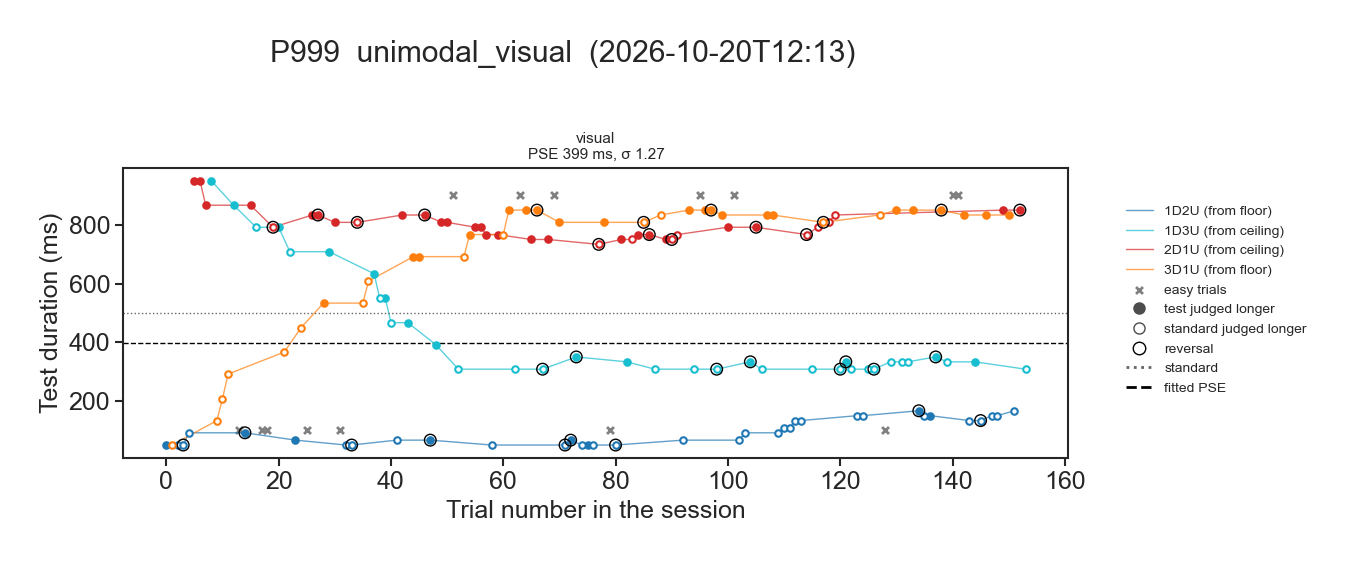

,condition,staircase,start,trials,reversals,first_ms,last_ms,mean_after_2nd_reversal_ms,share_test_longer
0,visual,1D2U,floor,35,9,50,167,99,0.23
1,visual,1D3U,ceiling,35,8,950,308,322,0.40
2,visual,2D1U,ceiling,35,10,950,850,789,0.71
3,visual,3D1U,floor,35,5,50,833,836,0.60


In [3]:
PID, TASK, BLOCK = 'P999', 'unimodal_visual', None
pick = sessions[(sessions.participant == PID) & (sessions.task == TASK)]
if BLOCK:
    pick = pick[pick.block == BLOCK]
if pick.empty:                                       # fall back to the first session in the folder
    pick = sessions.iloc[[0]]
meta = pick.iloc[-1]
d = pd.read_csv(meta.csv)
fig = plot_staircases(d, f"{meta.participant}  {meta.task}{' ' + meta.block if meta.block else ''}  ({meta.started[:16]})")
plt.show()
staircase_summary(d)

## Every unimodal and cross-modal session in the folder

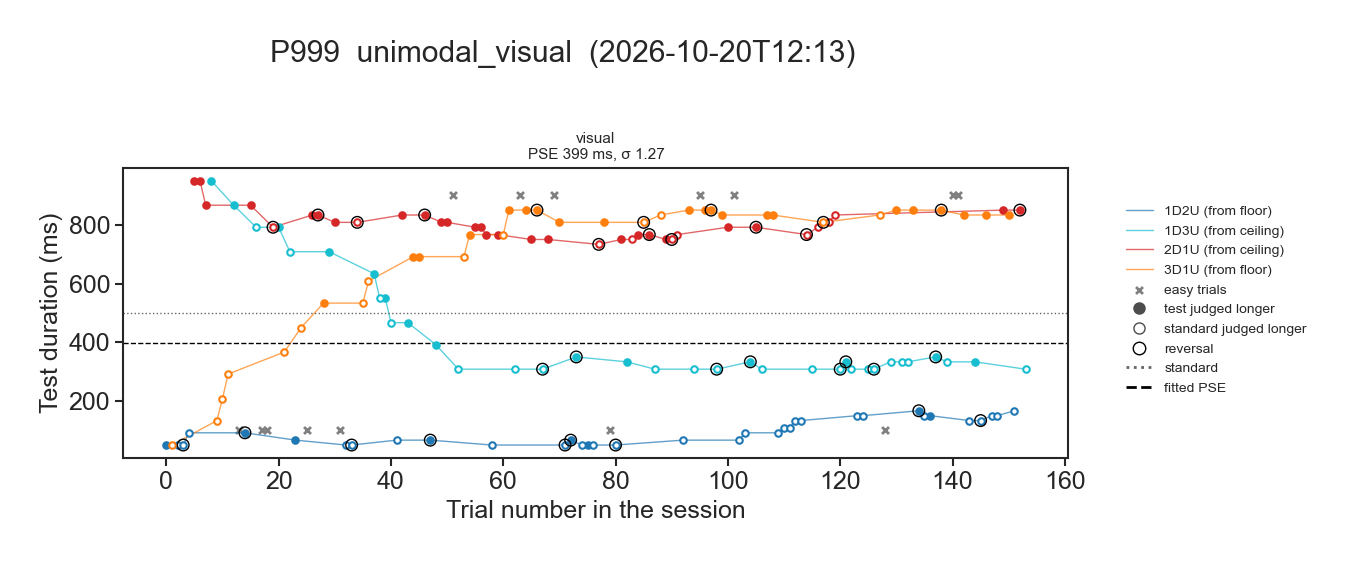

In [4]:
for _, meta in sessions[sessions.task != 'main'].iterrows():
    d = pd.read_csv(meta.csv)
    plot_staircases(d, f"{meta.participant}  {meta.task}  ({meta.started[:16]})")
    plt.show()

## Main-experiment blocks

One figure per block: rows are noise levels, columns are conflicts.

In [5]:
for _, meta in sessions[sessions.task == 'main'].iterrows():
    d = pd.read_csv(meta.csv)
    plot_staircases(d, f"{meta.participant}  main {meta.block}  ({meta.started[:16]})")
    plt.show()